<a href="https://colab.research.google.com/github/juanchomvasquez/premier-league-dna/blob/main/01_midfield_style_prototype.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Premier League DNA — Consolidated Midfield Prototype

Synthetic player actions → evidence-backed measurements → experimental style references → changing match stories.

**Model version: 0.1.** All reference rates are invented design assumptions, not historical statistics. Scores measure distance to these settings; they are not probabilities, greatness ratings, or calibrated historical similarity.

## Scope and limitations
- Three fictional midfielders; player-action samples, not a possession-consistent full match.
- Coordinates are normalized to 0–100; distance is not in meters. All players attack toward x=100.
- Progression means at least 25% reduction in distance to the goal center, under this prototype definition.
- Windows are start-exclusive and end-inclusive. Sequences crossing boundaries can appear in adjacent windows; whole-sequence attribution is future work.
- Recorded box touches duplicate arrivals in this generator and receive zero comparison weight.
- Other correlated measurements remain; equal dimension weights do not establish statistical independence.
- Evidence checks verify consistency, not football validity. Weight sensitivity is not historical validation.
- No Microsoft service is called by this notebook.


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Initial design hypotheses—we will refine these before final scoring.
profile_parameters = pd.DataFrame([
    {
        "profile": "Lampard-inspired",
        "dimension": "Attacking involvement",
        "measure_1": "Off-ball arrivals into the penalty area",
        "measure_2": "Shots",
        "measure_3": "Touches inside the opposition penalty area",
    },
    {
        "profile": "Gerrard-inspired",
        "dimension": "Progression",
        "measure_1": "Progressive passes",
        "measure_2": "Progressive carries",
        "measure_3": "Passes entering the final third",
    },
    {
        "profile": "Scholes-inspired",
        "dimension": "Distribution",
        "measure_1": "Completed passes",
        "measure_2": "Completed switches of play",
        "measure_3": "Completed long passes",
    },
])

display(profile_parameters)

,profile,dimension,measure_1,measure_2,measure_3
0,Lampard-inspired,Attacking involvement,Off-ball arrivals into the penalty area,Shots,Touches inside the opposition penalty area
1,Gerrard-inspired,Progression,Progressive passes,Progressive carries,Passes entering the final third
2,Scholes-inspired,Distribution,Completed passes,Completed switches of play,Completed long passes


In [20]:
import json
from IPython.display import display

# Group the measurements into our three proposed style dimensions.
# These are raw counts, not similarity scores or historical comparisons.
profile_groups = {
    "Lampard-inspired\nAttacking involvement": [
        "Box arrivals",
        "Shots",
        "Recorded box touches"
    ],
    "Gerrard-inspired\nProgression": [
        "Progressive passes",
        "Progressive carries",
        "Passes entering final third"
    ],
    "Scholes-inspired\nDistribution": [
        "Completed passes",
        "Completed switches",
        "Completed long passes"
    ]
}



## 1. One reusable measurement function

In [21]:
def analyze_player(data, player, start_minute=0, end_minute=45):
    """Return measurements and evidence for (start_minute, end_minute]."""
    if start_minute >= end_minute:
        raise ValueError("Start minute must be before end minute.")
    if player not in data["player"].values:
        raise ValueError(f"Unknown player: {player}")

    d = data.loc[
        data["player"].eq(player)
        & data["minute"].gt(start_minute)
        & data["minute"].le(end_minute)
    ].copy()

    completed_pass = d["event_type"].eq("pass") & d["completed"]
    completed_carry = d["event_type"].eq("carry") & d["completed"]

    start_distance = np.hypot(100 - d["start_x"], 50 - d["start_y"])
    end_distance = np.hypot(100 - d["end_x"], 50 - d["end_y"])
    reduction = (
        (start_distance - end_distance)
        / start_distance.replace(0, np.nan)
    )

    start_box = d["start_x"].ge(84) & d["start_y"].between(21, 79)
    end_box = d["end_x"].ge(84) & d["end_y"].between(21, 79)

    lateral = abs(d["end_y"] - d["start_y"])
    distance = np.hypot(
        d["end_x"] - d["start_x"],
        d["end_y"] - d["start_y"]
    )
    crosses_center = (
        (d["start_y"].lt(50) & d["end_y"].gt(50))
        | (d["start_y"].gt(50) & d["end_y"].lt(50))
    )

    conditions = {
        "Box arrivals": (
            d["event_type"].eq("box_arrival")
            & d["completed"] & ~start_box & end_box
        ),
        "Shots": d["event_type"].eq("shot"),
        "Recorded box touches": d["event_type"].eq("touch") & start_box,
        "Progressive passes": completed_pass & reduction.ge(0.25),
        "Progressive carries": completed_carry & reduction.ge(0.25),
        "Passes entering final third": (
            completed_pass
            & d["start_x"].lt(100 * 2 / 3)
            & d["end_x"].ge(100 * 2 / 3)
        ),
        "Completed passes": completed_pass,
        "Completed switches": (
            completed_pass & crosses_center & lateral.ge(50)
        ),
        "Completed long passes": completed_pass & distance.ge(30)
    }

    return {
        "player": player,
        "start_minute_exclusive": start_minute,
        "end_minute_inclusive": end_minute,
        "recorded_events": len(d),
        "data_type": "synthetic demonstration",
        "measurements": [
            {
                "measurement": name,
                "count": int(condition.sum()),
                "event_ids": d.loc[condition, "event_id"].tolist()
            }
            for name, condition in conditions.items()
        ]
    }




## 2. Reproducible synthetic player actions

In [22]:
def generate_midfield_events(seed=42):
    rng = np.random.default_rng(seed)
    rows = []

    # Probabilities: pass, carry, attacking sequence.
    player_settings = {
        "Alex Morganfield": [
            [0.80, 0.15, 0.05],  # Minutes 0–30: distribution emphasis
            [0.65, 0.25, 0.10],  # Minutes 30–60: more carrying
            [0.55, 0.25, 0.20],  # Minutes 60–90: more attacking
        ],
        "Ben Calder": [
            [0.85, 0.10, 0.05],
            [0.85, 0.10, 0.05],
            [0.85, 0.10, 0.05],
        ],
        "Diego Mercer": [
            [0.60, 0.30, 0.10],
            [0.60, 0.30, 0.10],
            [0.60, 0.30, 0.10],
        ],
    }

    def add_event(player, minute, kind, sx, sy, ex, ey,
                  completed, sequence_id, shot_outcome=None):
        rows.append({
            "minute": minute,
            "event_type": kind,
            "start_x": sx, "start_y": sy,
            "end_x": ex, "end_y": ey,
            "completed": completed,
            "shot_outcome": shot_outcome,
            "sequence_id": sequence_id,
            "player": player,
            "team": "Northbridge FC",
            "synthetic": True
        })

    for player, phases in player_settings.items():
        # Same number of action opportunities for each player.
        times = np.sort(rng.uniform(0.1, 89.8, size=60))

        for number, minute in enumerate(times, start=1):
            phase = min(int(minute // 30), 2)
            action = rng.choice(
                ["pass", "carry", "attack"],
                p=phases[phase]
            )
            sequence_id = f"{player.split()[0]}_SEQ_{number:03d}"

            sx = float(rng.uniform(25, 75))
            sy = float(rng.uniform(10, 90))

            if action == "pass":
                # Include occasional wide switches.
                if rng.random() < 0.20:
                    sy = float(rng.uniform(10, 20))
                    ey = float(rng.uniform(80, 90))
                    if rng.random() < 0.5:
                        sy, ey = ey, sy
                    ex = float(np.clip(sx + rng.uniform(-5, 20), 0, 100))
                else:
                    ex = float(np.clip(sx + rng.uniform(-15, 35), 0, 100))
                    ey = float(np.clip(sy + rng.uniform(-25, 25), 0, 100))

                add_event(
                    player, minute, "pass", sx, sy, ex, ey,
                    bool(rng.random() < 0.85), sequence_id
                )

            elif action == "carry":
                ex = float(np.clip(sx + rng.uniform(5, 30), 0, 100))
                ey = float(np.clip(sy + rng.uniform(-10, 10), 0, 100))

                add_event(
                    player, minute, "carry", sx, sy, ex, ey,
                    bool(rng.random() < 0.90), sequence_id
                )

            else:
                # Related events share a sequence ID.
                bx = float(rng.uniform(85, 95))
                by = float(rng.uniform(30, 70))

                add_event(
                    player, minute, "box_arrival",
                    78, by, bx, by, True, sequence_id
                )
                add_event(
                    player, minute + 0.02, "touch",
                    bx, by, bx, by, True, sequence_id
                )

                if rng.random() < 0.55:
                    outcome = rng.choice(
                        ["goal", "saved", "off_target", "blocked"],
                        p=[0.12, 0.35, 0.33, 0.20]
                    )
                    add_event(
                        player, minute + 0.04, "shot",
                        bx, by, 100, 50,
                        bool(outcome == "goal"),
                        sequence_id,
                        shot_outcome=str(outcome)
                    )

    result = pd.DataFrame(rows).sort_values(
        ["minute", "player"], kind="stable"
    ).reset_index(drop=True)

    result.insert(
        0, "event_id",
        [f"SYN_{i:04d}" for i in range(1, len(result) + 1)]
    )

    return result


synthetic_events = generate_midfield_events()

display(synthetic_events.head(10))
display(pd.crosstab(
    synthetic_events["player"],
    synthetic_events["event_type"]
))

print(f"Generated {len(synthetic_events)} synthetic events.")

,event_id,minute,event_type,start_x,start_y,end_x,end_y,completed,shot_outcome,sequence_id,player,team,synthetic
0,SYN_0001,0.307097,pass,31.290351,17.337894,49.066238,25.483380,True,None,Diego_SEQ_001,Diego Mercer,Northbridge FC,True
1,SYN_0002,0.760396,pass,48.554810,55.218889,65.290726,57.897859,True,None,Alex_SEQ_001,Alex Morganfield,Northbridge FC,True
2,SYN_0003,1.062270,pass,29.002464,70.426414,37.468811,52.960063,True,None,Ben_SEQ_001,Ben Calder,Northbridge FC,True
3,SYN_0004,1.417051,carry,27.232454,28.628183,39.533938,28.432134,True,None,Ben_SEQ_002,Ben Calder,Northbridge FC,True
4,SYN_0005,3.710760,pass,34.890492,72.252114,32.224511,80.644572,True,None,Diego_SEQ_002,Diego Mercer,Northbridge FC,True
5,SYN_0006,4.029198,pass,26.540892,44.937391,31.967324,62.607545,True,None,Alex_SEQ_002,Alex Morganfield,Northbridge FC,True
6,SYN_0007,4.594570,pass,31.932725,32.681661,62.449070,17.807782,True,None,Diego_SEQ_003,Diego Mercer,Northbridge FC,True
7,SYN_0008,5.084442,pass,29.205767,29.493396,46.085202,36.950849,True,None,Ben_SEQ_003,Ben Calder,Northbridge FC,True
8,SYN_0009,5.667061,carry,72.646123,58.804839,84.023797,61.314402,True,None,Diego_SEQ_004,Diego Mercer,Northbridge FC,True
9,SYN_0010,5.824408,pass,39.069195,33.487501,51.920802,47.682411,True,None,Alex_SEQ_003,Alex Morganfield,Northbridge FC,True


event_type,box_arrival,carry,pass,shot,touch
player,,,,,
Alex Morganfield,8,10,42,4,8
Ben Calder,2,6,52,0,2
Diego Mercer,7,17,36,4,7


Generated 205 synthetic events.


In [23]:
player_reports = {}
comparison_rows = []

for player in synthetic_events["player"].unique():
    report = analyze_player(
        synthetic_events,
        player,
        start_minute=0,
        end_minute=90
    )
    player_reports[player] = report

    comparison_rows.append({
        "player": player,
        **{
            item["measurement"]: item["count"]
            for item in report["measurements"]
        }
    })

player_comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("player")
    .sort_index()
)

display(player_comparison)

# Confirm equal numbers of generated action sequences.
sequence_counts = (
    synthetic_events.groupby("player")["sequence_id"]
    .nunique()
    .rename("action_sequences")
)

display(sequence_counts)
assert sequence_counts.eq(60).all()

print("Verified: each player has 60 action sequences.")

,Box arrivals,Shots,Recorded box touches,Progressive passes,Progressive carries,Passes entering final third,Completed passes,Completed switches,Completed long passes
player,,,,,,,,,
Alex Morganfield,8,4,8,8,5,10,38,9,13
Ben Calder,2,0,2,8,4,11,44,7,16
Diego Mercer,7,4,7,8,8,7,28,5,10


,action_sequences
player,
Alex Morganfield,60
Ben Calder,60
Diego Mercer,60


Verified: each player has 60 action sequences.


## 3. Sequence coverage and match changes
Coverage is descriptive activity, not resemblance. Dimensions overlap.

In [24]:
def calculate_sequence_blend(data, player, start=0, end=90):
    report = analyze_player(data, player, start, end)

    selected = data.loc[
        data["player"].eq(player)
        & data["minute"].gt(start)
        & data["minute"].le(end)
    ]

    total_sequences = selected["sequence_id"].nunique()

    evidence_by_metric = {
        item["measurement"]: set(item["event_ids"])
        for item in report["measurements"]
    }

    rows = []

    for profile, measurements in profile_groups.items():
        supporting_ids = set().union(*[
            evidence_by_metric[measurement]
            for measurement in measurements
        ])

        supporting_sequences = selected.loc[
            selected["event_id"].isin(supporting_ids),
            "sequence_id"
        ].unique()

        rows.append({
            "player": player,
            "profile": profile.replace("\n", " — "),
            "supporting_sequences": len(supporting_sequences),
            "total_sequences": total_sequences,
            "sequence_coverage_pct": (
                round(100 * len(supporting_sequences)
                      / total_sequences, 1)
                if total_sequences else np.nan
            )
        })

    return pd.DataFrame(rows)


sequence_blends = pd.concat([
    calculate_sequence_blend(synthetic_events, player)
    for player in sorted(synthetic_events["player"].unique())
], ignore_index=True)

sequence_blend_table = sequence_blends.pivot(
    index="player",
    columns="profile",
    values="sequence_coverage_pct"
)

display(sequence_blend_table)

profile,Gerrard-inspired — Progression,Lampard-inspired — Attacking involvement,Scholes-inspired — Distribution
player,,,
Alex Morganfield,28.3,13.3,63.3
Ben Calder,30.0,3.3,73.3
Diego Mercer,31.7,11.7,46.7


,window,profile,supporting_sequences,total_sequences,sequence_coverage_pct
0,0–30,Lampard-inspired — Attacking involvement,2,18,11.1
1,0–30,Gerrard-inspired — Progression,1,18,5.6
2,0–30,Scholes-inspired — Distribution,13,18,72.2
3,30–60,Lampard-inspired — Attacking involvement,1,17,5.9
4,30–60,Gerrard-inspired — Progression,5,17,29.4
5,30–60,Scholes-inspired — Distribution,10,17,58.8
6,60–90,Lampard-inspired — Attacking involvement,5,25,20.0
7,60–90,Gerrard-inspired — Progression,11,25,44.0
8,60–90,Scholes-inspired — Distribution,15,25,60.0


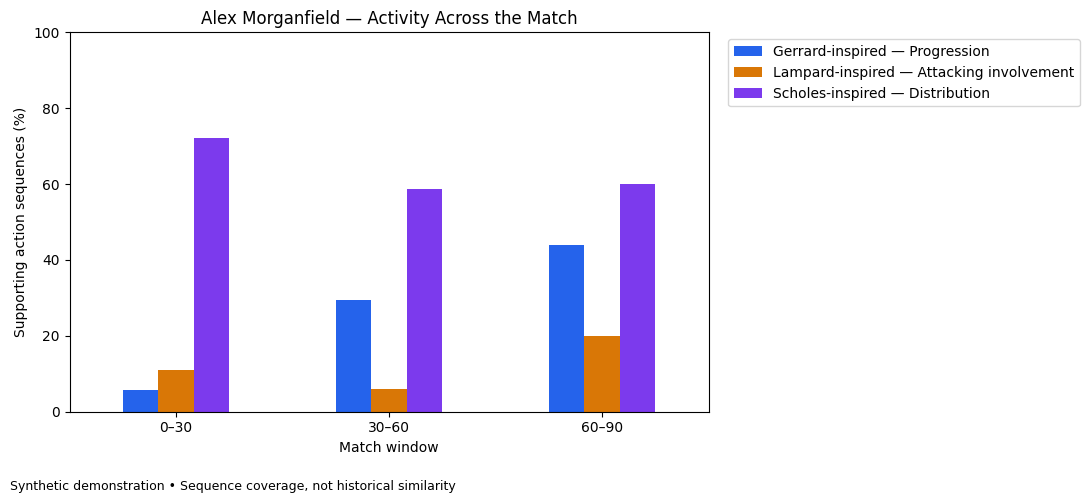

In [25]:
match_phases = [
    ("0–30", 0, 30),
    ("30–60", 30, 60),
    ("60–90", 60, 90)
]

alex_phase_results = []

for label, start, end in match_phases:
    phase = calculate_sequence_blend(
        synthetic_events,
        "Alex Morganfield",
        start,
        end
    )
    phase["window"] = label
    alex_phase_results.append(phase)

alex_phase_results = pd.concat(
    alex_phase_results, ignore_index=True
)

display(alex_phase_results[[
    "window",
    "profile",
    "supporting_sequences",
    "total_sequences",
    "sequence_coverage_pct"
]])

phase_chart = alex_phase_results.pivot(
    index="window",
    columns="profile",
    values="sequence_coverage_pct"
).reindex(index=[label for label, _, _ in match_phases])

ax = phase_chart.plot(
    kind="bar",
    figsize=(11, 5),
    color=["#2563EB", "#D97706", "#7C3AED"]
)

ax.set_title("Alex Morganfield — Activity Across the Match")
ax.set_xlabel("Match window")
ax.set_ylabel("Supporting action sequences (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.figtext(
    0.01, 0.01,
    "Synthetic demonstration • Sequence coverage, not historical similarity",
    fontsize=9
)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

In [26]:
# Compare the first and final periods.
phase_comparison = alex_phase_results.pivot(
    index="profile",
    columns="window",
    values="sequence_coverage_pct"
)

phase_comparison["change_percentage_points"] = (
    phase_comparison["60–90"] - phase_comparison["0–30"]
).round(1)

display(
    phase_comparison[
        ["0–30", "60–90", "change_percentage_points"]
    ].sort_values("change_percentage_points", ascending=False)
)

biggest_increase = (
    phase_comparison["change_percentage_points"].idxmax()
)
change = phase_comparison.loc[
    biggest_increase, "change_percentage_points"
]

if change > 0:
    print(
        f"Largest increase: {biggest_increase}, "
        f"up {change:.1f} percentage points."
    )
else:
    print("No dimension increased between the first and final periods.")

window,0–30,60–90,change_percentage_points
profile,,,
Gerrard-inspired — Progression,5.6,44.0,38.4
Lampard-inspired — Attacking involvement,11.1,20.0,8.9
Scholes-inspired — Distribution,72.2,60.0,-12.2


Largest increase: Gerrard-inspired — Progression, up 38.4 percentage points.


In [27]:
def build_change_evidence(data, player):
    periods = {
        "opening": (0, 30),
        "closing": (60, 90)
    }

    period_evidence = {}

    for label, (start, end) in periods.items():
        measurements = analyze_player(data, player, start, end)
        coverage = calculate_sequence_blend(data, player, start, end)

        period_evidence[label] = {
            "start_minute_exclusive": start,
            "end_minute_inclusive": end,
            "measurements": measurements["measurements"],
            "activity_dimensions": coverage[[
                "profile",
                "supporting_sequences",
                "total_sequences",
                "sequence_coverage_pct"
            ]].to_dict(orient="records")
        }

    opening = {
        row["profile"]: row["sequence_coverage_pct"]
        for row in period_evidence["opening"]["activity_dimensions"]
    }
    closing = {
        row["profile"]: row["sequence_coverage_pct"]
        for row in period_evidence["closing"]["activity_dimensions"]
    }

    changes = [
        {
            "profile": profile,
            "change_percentage_points": round(
                closing[profile] - opening[profile], 1
            )
        }
        for profile in opening
    ]

    return {
        "player": player,
        "data_type": "synthetic demonstration",
        "comparison": "Opening 30 minutes versus closing 30 minutes",
        "periods": period_evidence,
        "changes": changes,
        "interpretation_limits": [
            "Coverage measures activity, not historical similarity.",
            "Dimensions can overlap.",
            "Changes are descriptive, not statistically validated.",
            "Do not infer tactical causes from these events alone.",
            "Compare supporting counts as well as percentages."
        ]
    }


change_evidence = build_change_evidence(
    synthetic_events, "Alex Morganfield"
)

print(json.dumps(change_evidence, indent=2))

{
  "player": "Alex Morganfield",
  "data_type": "synthetic demonstration",
  "comparison": "Opening 30 minutes versus closing 30 minutes",
  "periods": {
    "opening": {
      "start_minute_exclusive": 0,
      "end_minute_inclusive": 30,
      "measurements": [
        {
          "measurement": "Box arrivals",
          "count": 2,
          "event_ids": [
            "SYN_0034",
            "SYN_0050"
          ]
        },
        {
          "measurement": "Shots",
          "count": 2,
          "event_ids": [
            "SYN_0036",
            "SYN_0052"
          ]
        },
        {
          "measurement": "Recorded box touches",
          "count": 2,
          "event_ids": [
            "SYN_0035",
            "SYN_0051"
          ]
        },
        {
          "measurement": "Progressive passes",
          "count": 1,
          "event_ids": [
            "SYN_0002"
          ]
        },
        {
          "measurement": "Progressive carries",
          "count": 0,


In [28]:
def validate_change_evidence(data, package):
    assert data["event_id"].is_unique, "Duplicate event IDs found."

    for period_name, period in package["periods"].items():
        valid_events = data.loc[
            data["player"].eq(package["player"])
            & data["minute"].gt(period["start_minute_exclusive"])
            & data["minute"].le(period["end_minute_inclusive"])
        ]

        valid_ids = set(valid_events["event_id"])
        total_sequences = valid_events["sequence_id"].nunique()

        for measurement in period["measurements"]:
            ids = measurement["event_ids"]

            assert len(ids) == len(set(ids)), (
                f"Duplicate evidence in {measurement['measurement']}"
            )
            assert measurement["count"] == len(ids), (
                f"Count mismatch in {measurement['measurement']}"
            )
            assert set(ids).issubset(valid_ids), (
                f"Invalid evidence in {period_name}"
            )

        for dimension in period["activity_dimensions"]:
            assert dimension["total_sequences"] == total_sequences
            assert 0 <= dimension["supporting_sequences"] <= total_sequences

            expected = (
                round(
                    100 * dimension["supporting_sequences"]
                    / total_sequences, 1
                )
                if total_sequences else np.nan
            )

            assert (
                pd.isna(expected)
                and pd.isna(dimension["sequence_coverage_pct"])
            ) or expected == dimension["sequence_coverage_pct"]

    print("Passed: evidence IDs, counts, periods, and coverage arithmetic.")


validate_change_evidence(synthetic_events, change_evidence)

Passed: evidence IDs, counts, periods, and coverage arithmetic.


## 4. Feature rates and experimental references
Rates are per 100 action sequences. Reference values and weights are explicit modeling assumptions.

In [29]:
def build_style_features(data, player, start=0, end=90):
    report = analyze_player(data, player, start, end)

    selected = data.loc[
        data["player"].eq(player)
        & data["minute"].gt(start)
        & data["minute"].le(end)
    ]

    total_sequences = selected["sequence_id"].nunique()

    return {
        "player": player,
        "action_sequences": total_sequences,
        **{
            item["measurement"]: (
                100 * item["count"] / total_sequences
                if total_sequences else np.nan
            )
            for item in report["measurements"]
        }
    }


style_features = pd.DataFrame([
    build_style_features(synthetic_events, player)
    for player in sorted(synthetic_events["player"].unique())
]).set_index("player")

display(style_features.round(2))
print("Measurement columns show counts per 100 action sequences.")

,action_sequences,Box arrivals,Shots,Recorded box touches,Progressive passes,Progressive carries,Passes entering final third,Completed passes,Completed switches,Completed long passes
player,,,,,,,,,,
Alex Morganfield,60,13.33,6.67,13.33,13.33,8.33,16.67,63.33,15.00,21.67
Ben Calder,60,3.33,0.00,3.33,13.33,6.67,18.33,73.33,11.67,26.67
Diego Mercer,60,11.67,6.67,11.67,13.33,13.33,11.67,46.67,8.33,16.67


Measurement columns show counts per 100 action sequences.


In [30]:
feature_names = [item["measurement"] for item in analyze_player(
    synthetic_events, "Alex Morganfield", 0, 90
)["measurements"]]

# Experimental reference rates per 100 action sequences.
# These are design assumptions, NOT historical player statistics.
reference_profiles = pd.DataFrame({
    "Lampard-inspired": {
        "Box arrivals": 20,
        "Shots": 10,
        "Recorded box touches": 20,
        "Progressive passes": 10,
        "Progressive carries": 5,
        "Passes entering final third": 10,
        "Completed passes": 45,
        "Completed switches": 3,
        "Completed long passes": 8
    },
    "Gerrard-inspired": {
        "Box arrivals": 10,
        "Shots": 5,
        "Recorded box touches": 10,
        "Progressive passes": 20,
        "Progressive carries": 15,
        "Passes entering final third": 20,
        "Completed passes": 55,
        "Completed switches": 8,
        "Completed long passes": 15
    },
    "Scholes-inspired": {
        "Box arrivals": 3,
        "Shots": 2,
        "Recorded box touches": 3,
        "Progressive passes": 15,
        "Progressive carries": 3,
        "Passes entering final third": 15,
        "Completed passes": 75,
        "Completed switches": 15,
        "Completed long passes": 25
    }
}).T.reindex(columns=feature_names)

# Equal total weight for each dimension.
# Box touches get zero weight because our generator duplicates arrivals.
feature_weights = pd.Series({
    "Box arrivals": 1 / 6,
    "Shots": 1 / 6,
    "Recorded box touches": 0,
    "Progressive passes": 1 / 9,
    "Progressive carries": 1 / 9,
    "Passes entering final third": 1 / 9,
    "Completed passes": 1 / 9,
    "Completed switches": 1 / 9,
    "Completed long passes": 1 / 9
}).reindex(feature_names)

assert np.isclose(feature_weights.sum(), 1)

display(reference_profiles)
display(feature_weights.rename("comparison_weight").to_frame())

,Box arrivals,Shots,Recorded box touches,Progressive passes,Progressive carries,Passes entering final third,Completed passes,Completed switches,Completed long passes
Lampard-inspired,20,10,20,10,5,10,45,3,8
Gerrard-inspired,10,5,10,20,15,20,55,8,15
Scholes-inspired,3,2,3,15,3,15,75,15,25


,comparison_weight
Box arrivals,0.166667
Shots,0.166667
Recorded box touches,0.000000
Progressive passes,0.111111
Progressive carries,0.111111
Passes entering final third,0.111111
Completed passes,0.111111
Completed switches,0.111111
Completed long passes,0.111111


In [31]:
# Fixed scales derived from our experimental references.
# Adding another player will not change these scales.
feature_scales = reference_profiles.abs().max(axis=0).replace(0, 1)

def score_style_profiles(features):
    """Compare one player's feature rates with each reference."""
    player_vector = features.reindex(feature_names).astype(float)

    if not np.isfinite(player_vector.to_numpy()).all():
        raise ValueError("All feature values must be finite.")

    scaled_difference = (
        reference_profiles.subtract(player_vector, axis="columns")
        .divide(feature_scales, axis="columns")
    )

    distances = np.sqrt(
        scaled_difference.pow(2)
        .multiply(feature_weights, axis="columns")
        .sum(axis=1)
    )

    return pd.DataFrame({
        "weighted_distance": distances,
        "experimental_resemblance_score": 100 / (1 + distances)
    }).sort_values(
        "experimental_resemblance_score", ascending=False
    )


# Check that each reference matches itself exactly.
for profile in reference_profiles.index:
    result = score_style_profiles(reference_profiles.loc[profile])
    assert np.isclose(
        result.loc[profile, "experimental_resemblance_score"], 100
    )

# Compare all three fictional players.
player_style_scores = pd.DataFrame({
    player: score_style_profiles(
        style_features.loc[player]
    )["experimental_resemblance_score"]
    for player in style_features.index
}).T

display(player_style_scores.round(1))
print("Verified: every reference scores 100 against itself.")

,Gerrard-inspired,Lampard-inspired,Scholes-inspired
Alex Morganfield,77.9,70.9,75.9
Ben Calder,72.4,60.6,86.8
Diego Mercer,83.2,74.8,70.5


Verified: every reference scores 100 against itself.


In [32]:
def explain_profile_distance(player, profile):
    observed = style_features.loc[player, feature_names].astype(float)
    reference = reference_profiles.loc[profile, feature_names]

    scaled_difference = (observed - reference) / feature_scales
    contributions = scaled_difference.pow(2) * feature_weights

    explanation = pd.DataFrame({
        "player_rate": observed,
        "reference_rate": reference,
        "difference": observed - reference,
        "weighted_squared_difference": contributions
    })

    return explanation.loc[
        feature_weights.gt(0)
    ].sort_values(
        "weighted_squared_difference", ascending=False
    )


display(
    explain_profile_distance(
        "Alex Morganfield", "Gerrard-inspired"
    ).round(3)
)

,player_rate,reference_rate,difference,weighted_squared_difference
Completed switches,15.000,8,7.000,0.024
Progressive carries,8.333,15,-6.667,0.022
Progressive passes,13.333,20,-6.667,0.012
Completed long passes,21.667,15,6.667,0.008
Box arrivals,13.333,10,3.333,0.005
Shots,6.667,5,1.667,0.005
Passes entering final third,16.667,20,-3.333,0.003
Completed passes,63.333,55,8.333,0.001


## 5. Evolving resemblance and weight sensitivity
Scores use 100 / (1 + weighted distance). High scores are not calibrated confidence. Inspect mismatches and sample sizes.

,Lampard-inspired,Gerrard-inspired,Scholes-inspired
window,,,
0–30,64.1,59.6,65.2
30–60,60.8,74.1,78.9
60–90,68.5,76.6,64.5


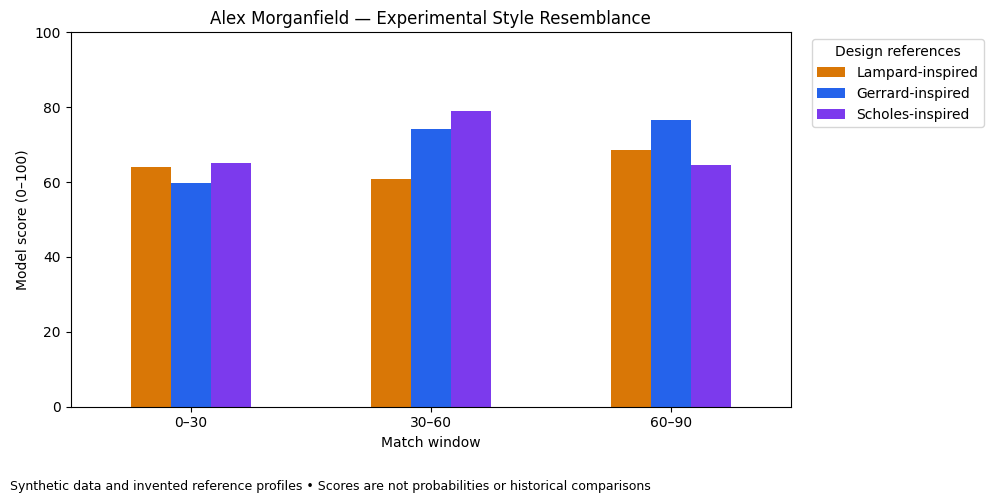

In [33]:
phase_score_rows = []

for label, start, end in match_phases:
    features = build_style_features(
        synthetic_events, "Alex Morganfield", start, end
    )

    scores = score_style_profiles(pd.Series(features))

    for profile, row in scores.iterrows():
        phase_score_rows.append({
            "window": label,
            "profile": profile,
            "action_sequences": features["action_sequences"],
            "resemblance_score": row[
                "experimental_resemblance_score"
            ]
        })

phase_style_scores = pd.DataFrame(phase_score_rows)

score_table = phase_style_scores.pivot(
    index="window",
    columns="profile",
    values="resemblance_score"
).reindex(
    index=[label for label, _, _ in match_phases],
    columns=reference_profiles.index
)

display(score_table.round(1))

ax = score_table.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#D97706", "#2563EB", "#7C3AED"]
)

ax.set_title("Alex Morganfield — Experimental Style Resemblance")
ax.set_xlabel("Match window")
ax.set_ylabel("Model score (0–100)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Design references", bbox_to_anchor=(1.02, 1))

plt.figtext(
    0.01, 0.01,
    "Synthetic data and invented reference profiles • "
    "Scores are not probabilities or historical comparisons",
    fontsize=9
)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

In [34]:
# Sensitivity check: vary each dimension's total weight by ±20%.
# Keep the existing feature scales and reference profiles fixed.

dimension_features = {
    "Attacking": ["Box arrivals", "Shots", "Recorded box touches"],
    "Progression": [
        "Progressive passes",
        "Progressive carries",
        "Passes entering final third"
    ],
    "Distribution": [
        "Completed passes",
        "Completed switches",
        "Completed long passes"
    ]
}

sensitivity_rows = []

for label, start, end in match_phases:
    features = pd.Series(build_style_features(
        synthetic_events, "Alex Morganfield", start, end
    )).reindex(feature_names).astype(float)

    squared_difference = (
        reference_profiles.subtract(features, axis="columns")
        .divide(feature_scales, axis="columns")
        .pow(2)
    )

    for dimension, columns in dimension_features.items():
        for multiplier in [0.8, 1.2]:
            weights = feature_weights.copy()
            weights.loc[columns] *= multiplier
            weights /= weights.sum()

            distances = np.sqrt(
                squared_difference.mul(weights, axis="columns").sum(axis=1)
            )

            sensitivity_rows.append({
                "window": label,
                "weight_change": f"{dimension} × {multiplier}",
                "closest_reference": distances.idxmin()
            })

sensitivity_results = pd.DataFrame(sensitivity_rows)

display(sensitivity_results.pivot(
    index="weight_change",
    columns="window",
    values="closest_reference"
).reindex(columns=[label for label, _, _ in match_phases]))

window,0–30,30–60,60–90
weight_change,,,
Attacking × 0.8,Scholes-inspired,Scholes-inspired,Gerrard-inspired
Attacking × 1.2,Scholes-inspired,Scholes-inspired,Gerrard-inspired
Distribution × 0.8,Lampard-inspired,Scholes-inspired,Gerrard-inspired
Distribution × 1.2,Scholes-inspired,Scholes-inspired,Gerrard-inspired
Progression × 0.8,Scholes-inspired,Scholes-inspired,Gerrard-inspired
Progression × 1.2,Scholes-inspired,Scholes-inspired,Gerrard-inspired


## Next implementation work
1. Validate coordinate conventions and event outcomes; attribute complete sequences consistently.
2. Research and document defensible reference profiles; test score calibration and low-activity behavior.
3. Extract analysis functions into an application module with explicit model configuration.
4. Add player selection and match replay with evidence inspection.
5. Connect Microsoft Foundry explanations to calculated evidence; verify current account access and APIs before implementation.
6. Add audience and language controls, deploy, and prepare the submission demonstration.

The three toy references provide a prototype of the concept, not a validated comparison with the named players.


In [35]:
import ipywidgets as widgets
from IPython.display import display, clear_output

player_selector = widgets.Dropdown(
    options=sorted(synthetic_events["player"].unique()),
    description="Player:"
)

minute_slider = widgets.IntSlider(
    value=30,
    min=1,
    max=90,
    step=1,
    description="Minute:",
    continuous_update=False
)

dashboard_output = widgets.Output()

def update_dashboard(change=None):
    with dashboard_output:
        clear_output(wait=True)

        player = player_selector.value
        minute = minute_slider.value

        features = build_style_features(
            synthetic_events, player, 0, minute
        )
        sequences = features["action_sequences"]

        print(f"{player} — through minute {minute}")
        print(f"Recorded action sequences: {sequences}")

        if sequences == 0:
            print("No recorded actions yet. Move the slider forward.")
            return

        # Temporary display threshold, not a validated reliability cutoff.
        if sequences < 10:
            print("Small sample: scores hidden until 10 action sequences.")
            return

        scores = score_style_profiles(
            pd.Series(features)
        ).reindex(reference_profiles.index)

        values = scores["experimental_resemblance_score"]

        fig, ax = plt.subplots(figsize=(8, 4))
        bars = ax.barh(
            values.index,
            values.values,
            color=["#D97706", "#2563EB", "#7C3AED"]
        )
        ax.invert_yaxis()
        ax.set_xlim(0, 100)
        ax.set_xlabel("Experimental resemblance score")
        ax.set_title(f"{player} — cumulative style profile")
        ax.bar_label(bars, fmt="%.1f", padding=4)
        plt.tight_layout()
        plt.show()

        print(
            "Synthetic data • Invented reference profiles • "
            "Scores are not similarity probabilities."
        )

        evidence = analyze_player(
            synthetic_events, player, 0, minute
        )
        display(pd.DataFrame(evidence["measurements"]))

player_selector.observe(update_dashboard, names="value")
minute_slider.observe(update_dashboard, names="value")

display(widgets.VBox([
    player_selector,
    minute_slider,
    dashboard_output
]))

update_dashboard()

In [38]:
view_selector = widgets.ToggleButtons(
    options=["Match so far", "Last 15 minutes"],
    description="View:"
)

def update_dashboard(change=None):
    with dashboard_output:
        clear_output(wait=True)

        player = player_selector.value
        end = minute_slider.value
        start = 0 if view_selector.value == "Match so far" else max(0, end - 15)

        features = build_style_features(
            synthetic_events, player, start, end
        )
        sequences = features["action_sequences"]

        print(f"{player} — minutes ({start}, {end}]")
        print(f"Recorded action sequences: {sequences}")

        if sequences == 0:
            print("No recorded actions in this window.")
            return

        if sequences < 10:
            print("Small sample: scores hidden until 10 action sequences.")
        else:
            scores = score_style_profiles(
                pd.Series(features)
            ).reindex(reference_profiles.index)

            values = scores["experimental_resemblance_score"]

            fig, ax = plt.subplots(figsize=(8, 4))
            bars = ax.barh(
                values.index,
                values.values,
                color=["#D97706", "#2563EB", "#7C3AED"]
            )
            ax.invert_yaxis()
            ax.set_xlim(0, 100)
            ax.set_xlabel("Experimental resemblance score")
            ax.set_title(f"{player} — {view_selector.value}")
            ax.bar_label(bars, fmt="%.1f", padding=4)
            plt.tight_layout()
            plt.show()

        print(
            "Synthetic data • Invented references • "
            "10-sequence display threshold is provisional."
        )

        evidence = analyze_player(
            synthetic_events, player, start, end
        )
        display(pd.DataFrame(evidence["measurements"]))


# Remove the earlier callback before registering the updated version.
player_selector.unobserve_all(name="value")
minute_slider.unobserve_all(name="value")

player_selector.observe(update_dashboard, names="value")
minute_slider.observe(update_dashboard, names="value")
view_selector.observe(update_dashboard, names="value")

display(widgets.VBox([
    player_selector,
    minute_slider,
    view_selector,
    dashboard_output
]))

update_dashboard()

In [39]:
def get_selected_story_input():
    player = player_selector.value
    end = minute_slider.value
    start = (
        0 if view_selector.value == "Match so far"
        else max(0, end - 15)
    )

    features = build_style_features(
        synthetic_events, player, start, end
    )
    sequence_count = features["action_sequences"]

    scores = []
    if sequence_count >= 10:
        result = score_style_profiles(pd.Series(features))

        scores = [
            {
                "reference": profile,
                "experimental_score": round(
                    float(row["experimental_resemblance_score"]), 1
                )
            }
            for profile, row in result.iterrows()
        ]

    return {
        "player": player,
        "view": view_selector.value,
        "window": {
            "start_exclusive": start,
            "end_inclusive": end
        },
        "action_sequences": int(sequence_count),
        "evidence": analyze_player(
            synthetic_events, player, start, end
        ),
        "experimental_reference_scores": scores,
        "audience": "casual fan",
        "language": "English",
        "instructions": [
            "Write a match insight in no more than 80 words.",
            "Use only the supplied measurements and scores.",
            "Describe references as invented legend-inspired profiles.",
            "Never describe scores as percentages of a legend.",
            "Explain the observed actions before mentioning resemblance.",
            "Do not claim a change over time without comparison evidence.",
            "Do not invent tactical causes or historical facts.",
            "Mention that this is a synthetic demonstration.",
            "If scores are absent, describe recorded actions only."
        ]
    }


selected_story_input = get_selected_story_input()
print(json.dumps(selected_story_input, indent=2))

{
  "player": "Alex Morganfield",
  "view": "Last 15 minutes",
  "window": {
    "start_exclusive": 28,
    "end_inclusive": 43
  },
  "action_sequences": 14,
  "evidence": {
    "player": "Alex Morganfield",
    "start_minute_exclusive": 28,
    "end_minute_inclusive": 43,
    "recorded_events": 16,
    "data_type": "synthetic demonstration",
    "measurements": [
      {
        "measurement": "Box arrivals",
        "count": 1,
        "event_ids": [
          "SYN_0050"
        ]
      },
      {
        "measurement": "Shots",
        "count": 1,
        "event_ids": [
          "SYN_0052"
        ]
      },
      {
        "measurement": "Recorded box touches",
        "count": 1,
        "event_ids": [
          "SYN_0051"
        ]
      },
      {
        "measurement": "Progressive passes",
        "count": 2,
        "event_ids": [
          "SYN_0070",
          "SYN_0087"
        ]
      },
      {
        "measurement": "Progressive carries",
        "count": 2,
        "